# Model Comparison – All Classification Models

Loads the 7 saved classifiers from the `models` folder and compares them on the **same test customers**.

> Run `python train_models.py` first so the model files exist.

In [1]:
import sys
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Use the same cleaning code as train_models.py
sys.path.append("..")
from train_models import load_and_clean_data, make_inputs

df = load_and_clean_data()
X = make_inputs(df)
y = df["high_value"]

models_dir = Path("../models")

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Test customers:", len(X_test))

Test customers: 406


In [2]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

models = [
    ("Logistic Regression", "classification", True),
    ("KNN", "knn", True),
    ("ANN", "ann", True),
    ("SVM", "svm", True),
    ("Decision Tree", "decision_tree", False),
    ("Naive Bayes", "naive_bayes", False),
    ("Random Forest", "random_forest", False),
]

results = []
matrices = {}

for name, prefix, uses_scaler in models:
    model = joblib.load(models_dir / f"{prefix}_model.pkl")
    data = X_test
    if uses_scaler:
        data = joblib.load(models_dir / f"{prefix}_scaler.pkl").transform(X_test)
    pred = model.predict(data)
    matrices[name] = confusion_matrix(y_test, pred)
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, pred) * 100, 2),
        "Precision": round(precision_score(y_test, pred) * 100, 2),
        "Recall": round(recall_score(y_test, pred) * 100, 2),
        "F1-Score": round(f1_score(y_test, pred) * 100, 2),
    })

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,90.64,88.02,94.09,90.95
4,Decision Tree,89.66,89.66,89.66,89.66
2,ANN,89.41,87.38,92.12,89.69
6,Random Forest,89.16,88.41,90.15,89.27
3,SVM,89.16,86.98,92.12,89.47
5,Naive Bayes,87.19,85.12,90.15,87.56
1,KNN,85.71,82.22,91.13,86.45


## Accuracy comparison chart

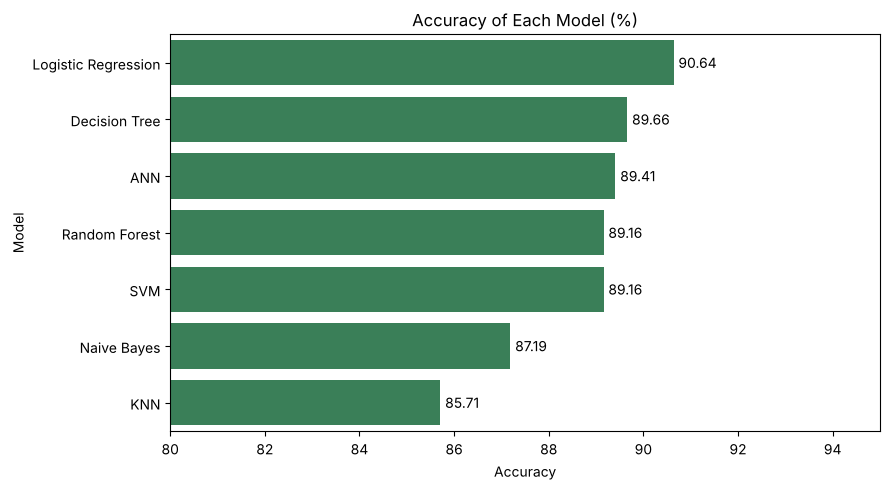

In [3]:
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Accuracy", y="Model", color="seagreen")
plt.xlim(80, 95)
plt.title("Accuracy of Each Model (%)")
for i, value in enumerate(results_df["Accuracy"]):
    plt.text(value + 0.1, i, str(value), va="center")
plt.tight_layout()
plt.show()

## All confusion matrices

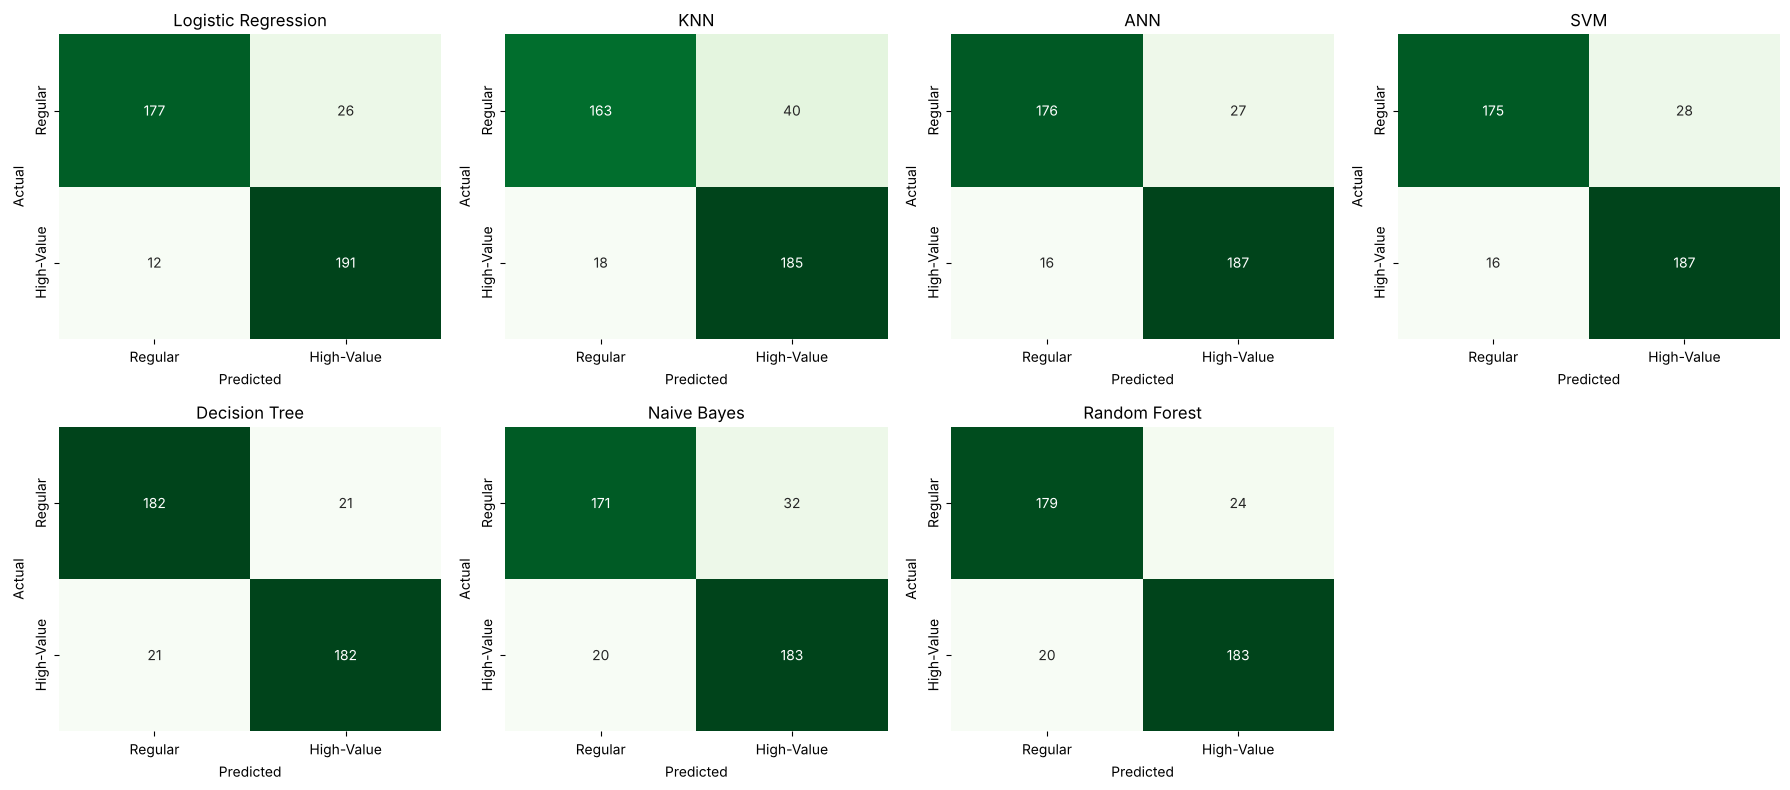

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for ax, (name, cm) in zip(axes, matrices.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax,
                xticklabels=["Regular", "High-Value"], yticklabels=["Regular", "High-Value"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

## Cross-Validation (are the results stable?)
One test split of 406 customers could be lucky. **5-fold cross-validation** trains and tests each model 5 times on different parts of the training data.
`make_pipeline(StandardScaler(), model)` re-learns the scaling inside each fold, so nothing leaks.

In [5]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

cv_models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    "ANN": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=2000, random_state=42)),
    "SVM": make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=42)),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for name, model in cv_models.items():
    scores = cross_val_score(model, X_train, y_train, cv=folds) * 100
    cv_rows.append({"Model": name, "CV Mean Accuracy": round(scores.mean(), 2), "Std": round(scores.std(), 2)})

cv_df = pd.DataFrame(cv_rows).sort_values("CV Mean Accuracy", ascending=False)
cv_df

,Model,CV Mean Accuracy,Std
6,Random Forest,89.90,1.63
0,Logistic Regression,89.65,2.08
4,Decision Tree,89.41,1.62
3,SVM,88.48,1.50
2,ANN,88.36,1.94
5,Naive Bayes,85.96,1.38
1,KNN,84.42,0.98


## Where do the models make mistakes?
We look at the customers that Logistic Regression (the best test model) got wrong.

In [6]:
model = joblib.load(models_dir / "classification_model.pkl")
scaler = joblib.load(models_dir / "classification_scaler.pkl")
pred = model.predict(scaler.transform(X_test))

wrong = df.loc[X_test.index[pred != y_test], ["income", "kids", "web_visits", "total_spending", "high_value"]]
wrong["predicted"] = pred[pred != y_test]

print("Wrong predictions:", len(wrong), "out of", len(X_test))
print("Called High-Value but actually Regular:", (wrong["predicted"] == 1).sum())
print("Called Regular but actually High-Value:", (wrong["predicted"] == 0).sum())
print("Wrong cases with income between 34,000 and 68,000:", wrong["income"].between(34000, 68000).sum())

wrong.sort_values("total_spending").head(10)

Wrong predictions: 38 out of 406
Called High-Value but actually Regular: 26
Called Regular but actually High-Value: 12
Wrong cases with income between 34,000 and 68,000: 34


,income,kids,web_visits,total_spending,high_value,predicted
666,45068.0,0,7,20,0,1
568,47691.0,0,6,21,0,1
1477,59892.0,0,3,87,0,1
1192,58401.0,0,4,96,0,1
617,162397.0,1,1,107,0,1
174,52074.0,0,4,119,0,1
441,56223.0,0,4,156,0,1
1950,51141.0,0,5,157,0,1
1193,62307.0,0,5,160,0,1
1740,55761.0,0,6,184,0,1


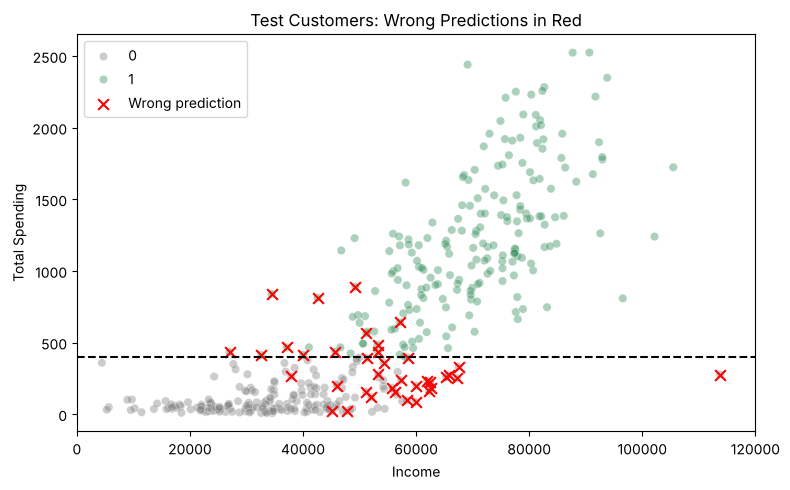

In [7]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df.loc[X_test.index], x="income", y="total_spending", hue="high_value", alpha=0.4, palette=["gray", "seagreen"])
plt.scatter(wrong["income"], wrong["total_spending"], color="red", marker="x", s=60, label="Wrong prediction")
plt.axhline(400, color="black", linestyle="--")
plt.xlim(0, 120000)
plt.title("Test Customers: Wrong Predictions in Red")
plt.xlabel("Income")
plt.ylabel("Total Spending")
plt.legend()
plt.tight_layout()
plt.show()

**What it explains:** Most mistakes (34 of 38) are customers with **middle incomes**, where High-Value and Regular customers overlap.
26 of them have a good income and usually no small children, so they *look* like High-Value customers, but they actually spent little.
The other 12 have lower incomes but spent more than expected. Their profile does not match their behaviour, and with only these columns no model can fully predict that.

## Final Interpretation
- On the test set, **Logistic Regression** is the best model (90.64%) and has the highest recall (94.09%), so it misses the fewest High-Value customers.
- In cross-validation, **Random Forest (89.90%)** and **Logistic Regression (89.65%)** are on top, followed closely by the Decision Tree. The standard deviation is about 1.5–2%, so the top five models are practically **tied**.
- **KNN** is the weakest because every column counts equally in its distance, even columns that do not matter much.
- Mistakes happen for customers whose spending does not match their profile, mostly in the middle income range.
- For a marketing team, **Logistic Regression** or the **Decision Tree** is the best choice: accurate **and** easy to explain.